In [2]:
import torch, transformers
print(torch.__version__, transformers.__version__)

/opt/miniconda3/envs/esm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.2.2 4.44.2


In [3]:
from transformers import AutoTokenizer, EsmForMaskedLM

name = "facebook/esm2_t12_35M_UR50D"
tok = AutoTokenizer.from_pretrained(name)
mlm = EsmForMaskedLM.from_pretrained(name).eval()

print(sum(p.numel() for p in mlm.parameters()) / 1e6, "M parameters")

/opt/miniconda3/envs/esm/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


33.993874 M parameters


In [4]:
aas = list("ACDEFGHIKLMNPQRSTVWY")
aa_ids = tok.convert_tokens_to_ids(aas)

ubq = "MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG"
print(len(ubq))
print(aa_ids)

76
[5, 23, 13, 9, 18, 6, 21, 12, 15, 4, 20, 17, 14, 16, 10, 8, 11, 7, 22, 19]


In [5]:
def predict(seq, pos):
    """pos is the 0-based residue index"""
    inp = tok(seq, return_tensors="pt")
    inp["input_ids"][0, pos + 1] = tok.mask_token_id
    with torch.no_grad():
        logits = mlm(**inp).logits[0, pos + 1]
    probs = torch.softmax(logits[aa_ids], dim=-1)
    return dict(zip(aas, probs.tolist()))

pos = 5
probs = predict(ubq, pos)
print("true residue:", ubq[pos])
for aa, p in sorted(probs.items(), key=lambda x: -x[1])[:5]:
    print(aa, round(p, 3))

true residue: K
K 0.788
R 0.151
Q 0.019
T 0.008
N 0.008


In [6]:
correct = 0
for i in range(len(ubq)):
    p = predict(ubq, i)
    if max(p, key=p.get) == ubq[i]:
        correct += 1

print(f"top-1 recovery: {correct}/{len(ubq)} = {correct/len(ubq):.2f}")

top-1 recovery: 40/76 = 0.53


In [7]:
import math

def mutation_score(seq, pos, mut):
    p = predict(seq, pos)
    return math.log(p[mut]) - math.log(p[seq[pos]])

print("K6R:", mutation_score(ubq, 5, "R"))
print("K6D:", mutation_score(ubq, 5, "D"))
print("K6W:", mutation_score(ubq, 5, "W"))

K6R: -1.650336772455194
K6D: -7.618358522901444
K6W: -8.449879631997709


In [8]:
pos = 5
wt = ubq[pos]
scores = {aa: mutation_score(ubq, pos, aa) for aa in aas if aa != wt}
for aa, s in sorted(scores.items(), key=lambda x: -x[1]):
    print(f"{wt}{pos+1}{aa}: {s:.2f}")

K6R: -1.65
K6Q: -3.70
K6T: -4.55
K6N: -4.62
K6H: -4.92
K6S: -5.10
K6E: -5.64
K6V: -5.78
K6L: -5.84
K6I: -5.86
K6A: -6.13
K6M: -6.78
K6C: -6.98
K6Y: -7.16
K6G: -7.26
K6F: -7.52
K6D: -7.62
K6W: -8.45
K6P: -9.75


In [9]:
import numpy as np

scan = np.zeros((len(ubq), 20))
for i in range(len(ubq)):
    p = predict(ubq, i)
    wt_logp = math.log(p[ubq[i]])
    for j, aa in enumerate(aas):
        scan[i, j] = math.log(p[aa]) - wt_logp

print(scan.shape)

mean_effect = scan.sum(axis=1) / 19
order = np.argsort(mean_effect)

print("Most sensitive positions:")
for i in order[:5]:
    print(f"  {ubq[i]}{i+1}: {mean_effect[i]:.2f}")
print("Most tolerant positions:")
for i in order[-5:][::-1]:
    print(f"  {ubq[i]}{i+1}: {mean_effect[i]:.2f}")

(76, 20)
Most sensitive positions:
  M1: -8.84
  L43: -8.48
  L56: -7.39
  I30: -7.07
  V5: -6.88
Most tolerant positions:
  K63: -0.14
  F4: -0.20
  N25: -0.56
  D39: -0.64
  R74: -0.95


In [10]:
np.save("ubq_scan.npy", scan)
print(np.load("ubq_scan.npy").shape)

(76, 20)


In [11]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


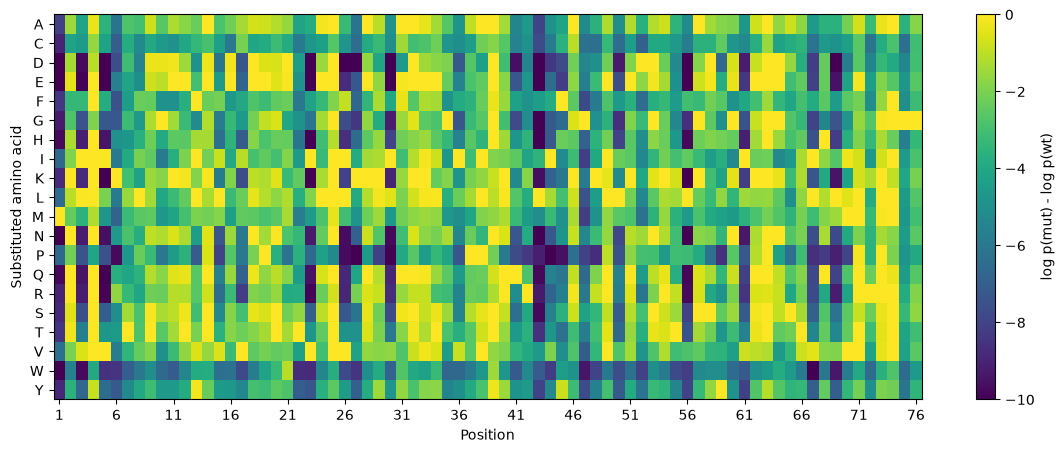

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(scan.T, aspect="auto", cmap="viridis", vmin=-10, vmax=0)
ax.set_yticks(range(20))
ax.set_yticklabels(aas)
ax.set_xticks(range(0, 76, 5))
ax.set_xticklabels(range(1, 77, 5))
ax.set_xlabel("Position")
ax.set_ylabel("Substituted amino acid")
fig.colorbar(im, label="log p(mut) - log p(wt)")
plt.show()

In [16]:
residue = 35         

pos = residue - 1
probs = predict(ubq, pos)
print(f"residue {residue}: true = {ubq[pos]}")
for aa, p in sorted(probs.items(), key=lambda x: -x[1])[:5]:
    print(aa, round(p, 3))

residue 35: true = G
G 0.438
N 0.125
S 0.097
K 0.07
D 0.063
